In [26]:

import argparse
import os
import numpy as np
from scipy.integrate import cumulative_trapezoid
import pynbody as pn
from pynbody.analysis.halo import shrink_sphere_center

G_PC = 4.30091e-3            # pc (km/s)^2 / Msun
A0_PC = 3.703                # (km/s)^2 / pc   (1.2e-10 m/s^2)
G_KPC = G_PC * 1e-3
A0_KPC = A0_PC * 1e3

In [27]:
def nu(y):
    return 0.5 + np.sqrt(0.25 + 1.0 / np.maximum(y, 1e-30))

def _g_host(R, M_func, mond):
    gN = G_KPC * M_func(R) / R ** 2
    return gN * nu(gN / A0_KPC) if mond else gN

def tidal_radius(R, m, M_func, mond=True, rel_dR=0.02):
    """Tidal radius [kpc] of a satellite of mass m at galactocentric radius R.
    MOND: Asencio et al. 2022 as in your helper file.
    DM  : King/Hill radius with centrifugal term."""
    dR = rel_dR * R
    g_c = float(_g_host(R, M_func, mond))
    g_hi, g_lo = float(_g_host(R + dR, M_func, mond)), float(_g_host(R - dR, M_func, mond))
    dg = abs(g_hi - g_lo) / (2 * dR)
    if dg == 0 or g_c <= 0:
        return np.nan
    if not mond:
        return (G_KPC * m / (g_c / R + dg)) ** (1.0 / 3.0)
    sqrt_f = np.sqrt((g_c + A0_KPC) / (g_c + 2 * A0_KPC))
    Geff = G_KPC * (g_c + A0_KPC) / g_c
    alpha = -(np.log(g_hi) - np.log(g_lo)) / (np.log(R + dR) - np.log(R - dR))
    bracket = (2 - alpha) / (3 - alpha) * Geff * m / dg
    return (2.0 / 3.0) * sqrt_f * bracket ** (1.0 / 3.0) if bracket > 0 else np.nan


def shrinking_sphere(pos, mass, r0, shrink=0.7, nmin=100, c0=None):
    """Shrinking-sphere centre (like pynbody's shrink_sphere_center), numpy only."""
    c = np.average(pos, weights=mass, axis=0) if c0 is None else np.asarray(c0, float)
    idx = np.arange(len(mass))
    r = r0
    last = c.copy()
    while True:
        d2 = np.sum((pos[idx] - c) ** 2, axis=1)
        sel = d2 < r * r
        if sel.sum() < nmin:
            return last
        idx = idx[sel]
        c = np.average(pos[idx], weights=mass[idx], axis=0)
        last = c
        r *= shrink

# ----------------------------------------------------------------------
# dwarf-internal gravity
# ----------------------------------------------------------------------
def g_newton(r_kpc, M_enc):
    return G_KPC * np.asarray(M_enc, float) / np.asarray(r_pc, float) ** 2

def g_mond(r_kpc, R_kpc, M_enc, M_host, efe=True):
    """MOND internal acceleration [(km/s)^2/pc] with QUMOND EFE. M_host must be the host mass ENCLOSED within R_kpc."""
    gN = g_newton_pc(r_pc, M_enc)
    if not efe:
        return nu(gN / A0_KPC) * gN
    gNe = g_newton_pc(R_kpc * 1e3, M_host)
    strong = gN > gNe
    out = np.empty_like(gN)
    y = gN[strong] / A0_KPC + gNe ** 2 / (3.0 * gN[strong] * A0_KPC)
    out[strong] = nu(y) * gN[strong]
    y = gNe / A0_KPC + gN[~strong] ** 2 / (3.0 * gNe * A0_KPC)
    out[~strong] = nu(y) * gN[~strong]
    return out

def bound_set(pos, vel, mass, c0, v0, r_init, c_host, nmin=50, max_iter=20, tol=0.01):
    """
    Select particles inside the Jacobi radius.
    Returns (mask, com, com_vel, converged) or None.
    """
    r = np.linalg.norm(pos - c0, axis=1)
    mask = r < r_init

    if mask.sum() < nmin:
        return None

    # Recompute the centre and velocity of the selected particles.
    com = np.average(pos[mask], weights=mass[mask], axis=0)
    comv = np.average(vel[mask], weights=mass[mask], axis=0)

    # Iterate the centre and radius cut until the selection stabilises.
    converged = False

    for _ in range(max_iter):
        r = np.linalg.norm(pos - com, axis=1)
        new = r < r_init

        if new.sum() < nmin:
            return None

        com_new = np.average(pos[new], weights=mass[new], axis=0)
        comv_new = np.average(vel[new], weights=mass[new], axis=0)

        stable = np.array_equal(new, mask)
        mask = new
        com, comv = com_new, comv_new

        if stable:
            converged = True
            break

    return mask, com, comv, converged

#def bound_set(pos, vel, mass, c0, v0, r_init, c_host, M_func, mond, efe,
              #r_edge=20.0, nmin=50, max_iter=20, tol=0.01):
    #"""Iterative energy-based bound selection (vectorised port of get_bound_center).
    #Dwarf self-gravity only: MOND(+EFE) for MOND runs, Newtonian for DM runs.
    #Returns (mask, com, com_vel, converged) or None."""
    #mask = np.linalg.norm(pos - c0, axis=1) < r_init
    #if mask.sum() < nmin:
    #    return None
    #com, comv = np.asarray(c0, float), np.asarray(v0, float)
    #converged = False
    #for _ in range(max_iter):
    #    idx = np.flatnonzero(mask)
    #    pb, vb, mb = pos[idx], vel[idx], mass[idx]
    #    r_kpc = np.linalg.norm(pb - com, axis=1)
     #   order = np.argsort(r_kpc)
    #    r_sorted, m_cumul = r_kpc[order], np.cumsum(mb[order])
    #    r_grid = np.geomspace(max(r_sorted[0], 1.0), r_edge, 500)
    #    m_grid = np.interp(r_grid, r_sorted, m_cumul)
    #    if mond:
    #        R = float(np.linalg.norm(com - c_host))
    #        g = g_mond(r_grid, R, m_grid, float(M_func(R)), efe)
    #    else:
    #        g = g_newton(r_grid, m_grid)
    #    phi = cumulative_trapezoid(g, r_grid, initial=0.0)
    #    phi -= phi[-1]
    #    phi_p = np.interp(r_pc, r_grid, phi, left=phi[0], right=0.0)
    #    new = (0.5 * np.sum((vb - comv) ** 2, axis=1) + phi_p) < 0.0
    #    if new.sum() < nmin:
    #        return None
    #    m_old, m_new = mb.sum(), mb[new].sum()
    #    mask[:] = False
    #    mask[idx[new]] = True
    #    com = np.average(pos[mask], weights=mass[mask], axis=0)
    #    comv = np.average(vel[mask], weights=mass[mask], axis=0)
    #    if abs(m_new - m_old) / (m_old + 1e-10) < tol:
    #        converged = True
    #        break
    #return mask, com, comv, converged

# ----------------------------------------------------------------------
# profiles
# ----------------------------------------------------------------------
def density_profile(pos, mass, centre, rbins):
    r = np.linalg.norm(pos - centre, axis=1)
    h, _ = np.histogram(r, bins=rbins, weights=mass)
    vol = 4.0 / 3.0 * np.pi * (rbins[1:] ** 3 - rbins[:-1] ** 3)
    return np.sqrt(rbins[1:] * rbins[:-1]), h / vol


def velocity_dispersion_profile(pos, vel, com_pos, com_vel, rbins, min_particles=20):
    """pos/vel and coms must be given in the HOST frame."""
    rel_pos, rel_vel = pos - com_pos, vel - com_vel
    r = np.linalg.norm(rel_pos, axis=1)
    L = np.cross(com_pos, com_vel)
    L_hat = L / max(np.linalg.norm(L), 1e-30)
    nb = len(rbins) - 1
    out = {k: np.full(nb, np.nan) for k in ("sr", "st1", "st2", "beta", "slos")}
    nn = np.zeros(nb, int)
    for j in range(nb):
        sh = (r >= rbins[j]) & (r < rbins[j + 1])
        nn[j] = sh.sum()
        if nn[j] < min_particles:
            continue
        rh = rel_pos[sh] / np.maximum(r[sh], 1e-10)[:, None]
        vv = rel_vel[sh]
        t2 = L_hat - np.sum(L_hat * rh, axis=1)[:, None] * rh
        t2 /= np.maximum(np.linalg.norm(t2, axis=1, keepdims=True), 1e-10)
        t1 = np.cross(t2, rh)
        t1 /= np.maximum(np.linalg.norm(t1, axis=1, keepdims=True), 1e-10)
        sr, s1, s2 = np.std(np.sum(vv * rh, 1)), np.std(np.sum(vv * t1, 1)), np.std(np.sum(vv * t2, 1))
        out["sr"][j], out["st1"][j], out["st2"][j] = sr, s1, s2
        out["beta"][j] = 1.0 - (s1 ** 2 + s2 ** 2) / (2 * sr ** 2 + 1e-10)
        out["slos"][j] = np.std(vv[:, 2])
    rc = np.sqrt(rbins[1:] * rbins[:-1])
    return rc, out, nn


def v_inf(M):
    return (G_KPC * M * A0_KPC) ** 0.25

def get_alpha(v, r, R, M):          # Brada & Milgrom 2000 (same as your helper)
    return (v * R / (r * v_inf(M))) ** (2 / 3)

def get_beta(v, r, R, M):
    return (v ** 2 * R) / (v_inf(M) ** 2 * r)

# ----------------------------------------------------------------------
# bar diagnostic of the live host disc
# ----------------------------------------------------------------------
def bar_diag(pos, mass, centre, rmax=30.0, nbins=30, zmax=1.0):
    p = pos - centre
    s = np.abs(p[:, 2]) < zmax
    R, phi, m = np.hypot(p[s, 0], p[s, 1]), np.arctan2(p[s, 1], p[s, 0]), mass[s]
    edges = np.linspace(0.5, rmax, nbins + 1)
    A2 = np.full(nbins, np.nan)
    Nn = np.zeros(nbins, int)
    ph = np.full(nbins, np.nan)
    for k in range(nbins):
        b = (R >= edges[k]) & (R < edges[k + 1])
        Nn[k] = b.sum()
        if Nn[k] > 0:
            c = np.sum(m[b] * np.exp(2j * phi[b]))
            A2[k], ph[k] = abs(c) / m[b].sum(), 0.5 * np.angle(c)
    inner = (R > 1) & (R < 5)
    c = np.sum(m[inner] * np.exp(2j * phi[inner])) if inner.any() else 0j
    return dict(A2_R=0.5 * (edges[1:] + edges[:-1]), A2_prof=A2, A2_N=Nn,
                A2_inner=abs(c) / max(m[inner].sum(), 1e-30), phase_inner=0.5 * np.angle(c))

# ----------------------------------------------------------------------
# one snapshot 
# ----------------------------------------------------------------------

def analyse_snapshot(pos, vel, mass, ids, P):
    """pos [kpc], vel [km/s], mass [Msun], ids: particle IDs (any order)."""
    o = np.argsort(ids, kind="stable")
    pos, vel, mass, ids = pos[o], vel[o], mass[o], ids[o]
    if len(np.unique(ids)) != len(ids):
        raise ValueError("duplicate particle IDs")
    N_host = P["n_host"]
    mond = P["mond"]
    host = ids <= N_host
    sat = ~host
    out = {}

    # ---- host ----
    ph, vh, mh = pos[host], vel[host], mass[host]
    c_host = shrinking_sphere(ph, mh, P["cutoff_host"])
    rh = np.linalg.norm(ph - c_host, axis=1)
    core = rh < 5.0
    v_host = np.average(vh[core], weights=mh[core], axis=0) if core.sum() > 10 else np.average(vh, weights=mh, axis=0)
    oo = np.argsort(rh)
    rs_h, Mc_h = rh[oo], np.cumsum(mh[oo])
    M_func = lambda r: np.interp(r, rs_h, Mc_h)
    bary = mh <= P["bary_mass_max"] if P["bary_mass_max"] else np.ones(len(mh), bool)
    out.update(host_com=c_host, host_vel=v_host, M_host=mh.sum(), M_host_bary=mh[bary].sum())
    if P["bar"]:
        out.update(bar_diag(ph[bary], mh[bary], c_host))

    # ---- dwarf ----
    ps, vs, ms, ids_s = pos[sat], vel[sat], mass[sat], ids[sat]
    is_star = (ids_s <= N_host + P["n_star"]) if P["n_star"] else np.ones(len(ms), bool)
    c0 = shrinking_sphere(ps, ms, P["sat_r0"], nmin=P["min_particles"], c0=np.average(ps, weights=ms, axis=0))
    near = np.linalg.norm(ps - c0, axis=1) < P["core_r"]
    v0 = np.average(vs[near], weights=ms[near], axis=0) if near.sum() > 5 else np.average(vs, weights=ms, axis=0)
    R = float(np.linalg.norm(c0 - c_host))

    # tidal radius, iterated with the mass inside it
    m_est = ms.sum()
    r_J = np.nan
    for _ in range(6):
        r_J = tidal_radius(R, m_est, M_func, mond)
        if not np.isfinite(r_J) or r_J <= 0:
            break
        m_new = ms[np.linalg.norm(ps - c0, axis=1) < r_J].sum() #new bound mass
        if m_new <= 0 or abs(m_new - m_est) / m_est < 0.01:
            m_est = max(m_new, m_est * 0 + m_new)
            break
        m_est = m_new
        
    res = None #initialize result dict.
    
    if np.isfinite(r_J) and r_J > 0:
        res = bound_set(ps, vs, ms, c0, v0, r_J, c_host, nmin=P["min_particles"])
    out.update(r_J=r_J, R=R, M_host_enc=float(M_func(R)))

    #radial bins
    nb = 24
    nan_prof = np.full(nb, np.nan)
    rb = np.geomspace(0.05, P["cutoff_sat"], nb + 1)
    rbd = np.geomspace(0.05, P["cutoff_sat"], 41)
    if res is None:
        out.update(ok=False, sat_com=c0, sat_vel_rel=v0 - v_host, M_bound=0.0, M_bound_star=0.0,
                   N_bound=0, converged=False, r50=np.nan, r90=np.nan, r99=np.nan, sigma=np.nan,
                   alpha=np.nan, beta_mond=np.nan, sig_r=nan_prof, sig_t1=nan_prof, sig_t2=nan_prof,
                   sig_los=nan_prof, aniso=nan_prof, rho_star=np.full(40, np.nan),
                   rho_all=np.full(40, np.nan), prof_r=np.sqrt(rb[1:] * rb[:-1]),
                   rho_r=np.sqrt(rbd[1:] * rbd[:-1]), n_prof=np.zeros(nb, int))
        out["sat_com_rel"] = c0 - c_host
        out["bound_mask_stars"] = None
        return out

    mask, com, comv, conv = res
    ms_b = mask & is_star
    pb, vb, mb = ps[ms_b], vs[ms_b], ms[ms_b]
    r = np.linalg.norm(pb - com, axis=1)
    o2 = np.argsort(r)
    mc = np.cumsum(mb[o2])
    r50, r90, r99 = (np.interp(f * mc[-1], mc, r[o2]) for f in (0.5, 0.9, 0.99))
    sigma = float(np.sqrt(sum(np.std(vb[:, k]) ** 2 for k in range(3))))
    rc, prof, nn = velocity_dispersion_profile(pb - c_host, vb - v_host, com - c_host,
                                              comv - v_host, rb)
    rr, rho_s = density_profile(pb, mb, com, rbd)
    _, rho_a = density_profile(ps[mask], ms[mask], com, rbd)
    M_b = P["bary_mass_max"] and out["M_host_bary"] or out["M_host"]
    out.update(ok=True, sat_com=com, sat_com_rel=com - c_host, sat_vel_rel=comv - v_host,
               M_bound=float(ms[mask].sum()), M_bound_star=float(mb.sum()), N_bound=int(mask.sum()),
               converged=conv, r50=r50, r90=r90, r99=r99, sigma=sigma,
               alpha=get_alpha(sigma, r99, R, out["M_host_bary"] if mond else M_b),
               beta_mond=get_beta(sigma, r99, R, out["M_host_bary"] if mond else M_b),
               sig_r=prof["sr"], sig_t1=prof["st1"], sig_t2=prof["st2"], sig_los=prof["slos"],
               aniso=prof["beta"], rho_star=rho_s, rho_all=rho_a, prof_r=rc, rho_r=rr, n_prof=nn)
    out["bound_mask_stars"] = None
    return out

# ----------------------------------------------------------------------
# I/O + parallel driver
# ----------------------------------------------------------------------
_P = {}

def _init(P):
    global _P
    _P = P
    os.environ["OMP_NUM_THREADS"] = "1"


def load_snapshot(path):
    s = pn.load(path)
    d = s.dm
    return (np.asarray(d["pos"].in_units("kpc"), float),
            np.asarray(d["vel"].in_units("km s^-1"), float),
            np.asarray(d["mass"].in_units("Msol"), float),
            np.asarray(d["iord"]).astype(np.int64))


def _work(i):
    path = os.path.join(_P["folder"], f"output_{i:05d}")
    pos, vel, mass, ids = load_snapshot(path)
    out = analyse_snapshot(pos, vel, mass, ids, _P)
    out.pop("bound_mask_stars", None)
    out["i"] = i
    return out

def analyse_run(folder, n_host, dt, i_end, i_start=1, mond=True, n_star=None,
                bary_mass_max=None, nproc=1, efe=None, bar=True,
                cutoff_host=400.0, cutoff_sat=20.0, min_particles=50,
                sat_r0=100.0, core_r=2.0):

    P = dict(
        folder=str(folder),
        n_host=n_host,
        mond=mond,
        efe=mond if efe is None else efe,
        n_star=n_star,
        bary_mass_max=bary_mass_max,
        bar=bar,
        cutoff_host=cutoff_host,
        cutoff_sat=cutoff_sat,
        min_particles=min_particles,
        sat_r0=sat_r0,
        core_r=core_r,
    )

    idx = list(range(i_start, i_end + 1))

    try:
        from tqdm.auto import tqdm
    except ImportError:
        tqdm = lambda x, **k: x
        
    if nproc == 1:
        _init(P)
        results = [ _work(i) for i in tqdm(idx, total=len(idx)) ]

    else:
        from multiprocessing import get_context
        with get_context("spawn").Pool(
            nproc, initializer=_init, initargs=(P,)
        ) as pool:
            results = list(tqdm(pool.imap(_work, idx), total=len(idx)))

    if not results:
        raise ValueError("No snapshots selected: check i_start and i_end.")

    res = {k: np.array([r[k] for r in results]) for k in results[0]}
    res["time_myr"] = (res["i"] - i_start) * dt
    return res

import os
import glob
import re

def get_max_file_number(directory):
    """
    Scans `directory` for entries named like 'output_00001' and returns
    the highest number found (as an int, so output_00101 -> 101).
    """
    entries = glob.glob(os.path.join(directory, "output_*"))
    numbers = []
    for e in entries:
        match = re.search(r"output_(\d+)", os.path.basename(e))
        if match:
            numbers.append(int(match.group(1)))
    if not numbers:
        raise FileNotFoundError(f"No 'output_#####' files found in {directory}")
    return max(numbers)


In [30]:
from pathlib import Path

# Folder containing output_00001, output_00002, ...
folder = Path("/Users/olgahinke/Desktop/simus/LCDM/300kpc_0.5")

# Simulation parameters
n_host = 1924444       # replace with actual number of host particles
n_star = 550000            # or number of dwarf star particles, if applicable
bary_mass_max = None     # set a mass threshold if needed

mond = False
dt = 100.0               # Myr between snapshots
i_start = 1
i_end = 98              # last snapshot number
nproc = 1
bar = True

# Run the analysis
res = analyse_run(
    folder=str(folder),
    n_host=n_host,
    dt=dt,
    i_end=i_end,
    i_start=i_start,
    mond=mond,
    n_star=n_star,
    bary_mass_max=bary_mass_max,
    nproc=nproc,
    bar=bar,
)

# Save the results
out_file = folder / "analysis_results.npz"
np.savez_compressed(out_file, **res)

print("Saved:", out_file)


  0%|          | 0/98 [00:00<?, ?it/s]/Users/olgahinke/venv/masterproject/lib/python3.12/site-packages/pynbody/snapshot/ramses.py:846: UserWarning: Using field at offset 9 to distinguish stars. If this is wrong, try editing your config.ini, section [ramses], entry particle-distinguisher.
  warnings.warn(
/Users/olgahinke/venv/masterproject/lib/python3.12/site-packages/pynbody/snapshot/ramses.py:1055: UserWarning: Namelist file either not found or unable to read. Guessing whether run is cosmological from cosmological parameters assuming flat LCDM.
  warnings.warn("Namelist file either not found or unable to read. " +
100%|██████████| 98/98 [05:33<00:00,  3.40s/it]

Saved: /Users/olgahinke/Desktop/simus/LCDM/300kpc_0.5/analysis_results.npz


In [ ]:
print(res.keys())


dict_keys(['host_com', 'host_vel', 'M_host', 'M_host_bary', 'A2_R', 'A2_prof', 'A2_N', 'A2_inner', 'phase_inner', 'r_J', 'R', 'M_host_enc', 'ok', 'sat_com', 'sat_com_rel', 'sat_vel_rel', 'M_bound', 'M_bound_star', 'N_bound', 'converged', 'r50', 'r90', 'r99', 'sigma', 'alpha', 'beta_mond', 'sig_r', 'sig_t1', 'sig_t2', 'sig_los', 'aniso', 'rho_star', 'rho_all', 'prof_r', 'rho_r', 'n_prof', 'i', 'time_myr'])


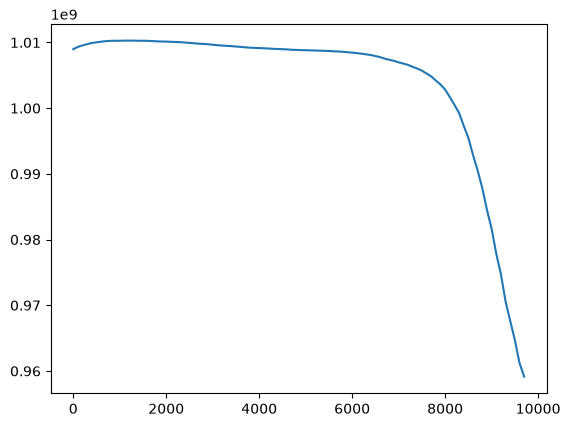

In [66]:
import matplotlib.pyplot as plt
plt.plot(res["time_myr"], res["M_bound"])
#plt.plot(*spl(u), '--', label="Fitted Spline")

In [51]:
from scipy.interpolate import make_splprep
t = np.array(res["time_myr"])
com = np.array(res["R"])
spl, u = make_splprep([t, com], s=0)   # note the [xn, yn] argument
spl_n, u_n = make_splprep([t, com], s=0.1)
deriv = spl.derivative() 
u_fine = np.linspace(u.min(), u.max(), 20000)
dcom_du = deriv(u_fine)[1]
# find sign changes in dcom/du -> extrema
sign_changes = np.where(np.diff(np.sign(dcom_du)))[0]

extrema_u = []
for i in sign_changes:
    # linear interpolation between u_fine[i] and u_fine[i+1] to refine the root
    u0, u1 = u_fine[i], u_fine[i+1]
    d0, d1 = dcom_du[i], dcom_du[i+1]
    u_root = u0 - d0 * (u1 - u0) / (d1 - d0)
    extrema_u.append(u_root)

extrema_u = np.array(extrema_u)
t_ext, com_ext = spl(extrema_u)

# classify: minima (pericenter) vs maxima (apocenter) via second derivative sign
d2com_du2 = spl.derivative(2)(extrema_u)[1]
pericenters = (t_ext[d2com_du2 > 0], com_ext[d2com_du2 > 0])
apocenters  = (t_ext[d2com_du2 < 0], com_ext[d2com_du2 < 0])
print("Pericenters (t, r):", pericenters)
print("Apocenters  (t, r):", apocenters)
print("Fitted mean eccentricity:", np.mean((apocenters[-1] - pericenters[-1])/(apocenters[-1] + pericenters[-1])))


Pericenters (t, r): (array([9682.0423852]), array([174.64517175]))
Apocenters  (t, r): (array([3702.15063378]), array([433.57273161]))
Fitted mean eccentricity: 0.42571512352005636
